# Data preparation

In [ ]:
from datasets import load_dataset

# 1. Load CoNLL-2003
dataset = load_dataset("lhoestq/conll2003")

# 2. Sample subsets (reproducible)
SEED = 42

train_dataset = dataset["train"].shuffle(seed=SEED).select(range(5000))
dev_dataset = dataset["validation"].shuffle(seed=SEED).select(range(1000))  
test_dataset = dataset["test"].shuffle(seed=SEED).select(range(500))

# 3. Print dataset information
print("=" * 45)
print("CoNLL-2003 Dataset Splits")
print("=" * 45)

print(f"Train: {len(train_dataset):,} sentences")
print(f"Dev:   {len(dev_dataset):,} sentences")
print(f"Test:  {len(test_dataset):,} sentences")

# 4. Display sample
print("\nExample from training set:")
print(train_dataset[0])

CoNLL-2003 Dataset Splits
Train: 5,000 sentences
Dev:   1,000 sentences
Test:  500 sentences

Example from training set:
{'id': '1469', 'tokens': ['"', 'Neither', 'the', 'National', 'Socialists', '(', 'Nazis', ')', 'nor', 'the', 'communists', 'dared', 'to', 'kidnap', 'an', 'American', 'citizen', ',', '"', 'he', 'shouted', ',', 'in', 'an', 'oblique', 'reference', 'to', 'his', 'extradition', 'to', 'Germany', 'from', 'Denmark', '.', '"'], 'pos_tags': [0, 12, 12, 22, 23, 4, 23, 5, 10, 12, 24, 38, 35, 37, 12, 16, 21, 6, 0, 28, 38, 6, 15, 12, 16, 21, 35, 29, 21, 35, 22, 15, 22, 7, 0], 'chunk_tags': [0, 11, 11, 12, 12, 0, 11, 0, 0, 11, 12, 21, 22, 22, 11, 12, 12, 0, 0, 11, 21, 0, 13, 11, 12, 12, 13, 11, 12, 13, 11, 13, 11, 12, 0], 'ner_tags': [0, 0, 0, 7, 8, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 5, 0, 0]}


# Baseline

In [25]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# CoNLL-2003 BIO label mapping
label_names = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

# Verify mapping
print("Labels:", label_names)
print("Sample tags:", train_dataset[0]["ner_tags"])
print("Decoded:", [
    label_names[int(tag)]
    for tag in train_dataset[0]["ner_tags"]
])

def extract_features(tokens, i):
    word = tokens[i]

    return {
        # Current token
        "word.lower": word.lower(),
        "word.isupper": word.isupper(),
        "word.istitle": word.istitle(),
        "word.isdigit": word.isdigit(),

        # Prefix / suffix
        "prefix2": word[:2].lower(),
        "prefix3": word[:3].lower(),
        "suffix2": word[-2:].lower(),
        "suffix3": word[-3:].lower(),

        # Context
        "prev.word": tokens[i - 1].lower()
            if i > 0 else "<START>",
        "next.word": tokens[i + 1].lower()
            if i < len(tokens) - 1 else "<END>",

        "prev.istitle": tokens[i - 1].istitle()
            if i > 0 else False,
        "next.istitle": tokens[i + 1].istitle()
            if i < len(tokens) - 1 else False,
    }

def prepare_data(data):
    X, y, lengths = [], [], []

    for example in data:
        tokens = example["tokens"]
        tags = example["ner_tags"]

        lengths.append(len(tokens))

        for i in range(len(tokens)):
            X.append(extract_features(tokens, i))
            y.append(tags[i])

    return X, np.array(y), lengths


X_train, y_train, train_lengths = prepare_data(train_dataset)
X_dev, y_dev, dev_lengths = prepare_data(dev_dataset)
X_test, y_test, test_lengths = prepare_data(test_dataset)

baseline_model = Pipeline([
    ("vectorizer", DictVectorizer(sparse=True)),
    ("classifier", LogisticRegression(
        max_iter=300,
        solver="lbfgs",
        random_state=42
    ))
])

start = time.time()

baseline_model.fit(X_train, y_train)

training_time = time.time() - start

print(f"Training completed in {training_time:.2f}s")

def to_sequences(flat_labels, lengths):
    sequences = []
    offset = 0

    for length in lengths:
        sequence = [
            label_names[int(tag)]
            for tag in flat_labels[offset:offset + length]
        ]

        sequences.append(sequence)
        offset += length

    return sequences

def evaluate_model(X, y, lengths, split_name):
    predictions = baseline_model.predict(X)

    y_true = to_sequences(y, lengths)
    y_pred = to_sequences(predictions, lengths)

    results = {
        "Split": split_name,
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

    print(f"\n{'=' * 50}")
    print(f"{split_name} Evaluation")
    print(f"{'=' * 50}")

    print(classification_report(y_true, y_pred, digits=4))

    return results


dev_results = evaluate_model(
    X_dev, y_dev, dev_lengths, "Dev"
)

test_results = evaluate_model(
    X_test, y_test, test_lengths, "Test"
)

results_df = pd.DataFrame([
    dev_results,
    test_results
])

print("\nBaseline Results:")
display(results_df.round(4))

output_path = Path("results/baseline_result.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(output_path, index=False)

print("\nBaseline Results:")
display(results_df.round(4))

print(f"\nResults saved to: {output_path.resolve()}")

# ============================================================
# 8. EXAMPLE PREDICTIONS
# ============================================================

example = dev_dataset[0]
tokens = example["tokens"]

features = [
    extract_features(tokens, i)
    for i in range(len(tokens))
]

predictions = baseline_model.predict(features)

print("\nExample NER Predictions:\n")

for token, pred in zip(tokens, predictions):
    print(f"{token:20} {label_names[int(pred)]}")

Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
Sample tags: [0, 0, 0, 7, 8, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 5, 0, 0]
Decoded: ['O', 'O', 'O', 'B-MISC', 'I-MISC', 'O', 'B-MISC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-MISC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-LOC', 'O', 'B-LOC', 'O', 'O']
Training completed in 18.69s

Dev Evaluation
              precision    recall  f1-score   support

         LOC     0.8609    0.8490    0.8549       576
        MISC     0.8043    0.8014    0.8028       282
         ORG     0.6093    0.6544    0.6310       379
         PER     0.7632    0.8276    0.7941       557

   micro avg     0.7656    0.7938    0.7794      1794
   macro avg     0.7594    0.7831    0.7707      1794
weighted avg     0.7685    0.7938    0.7806      1794


Test Evaluation
              precision    recall  f1-score   support

         LOC     0.7229    0

,Split,Precision,Recall,F1
0,Dev,0.7656,0.7938,0.7794
1,Test,0.6629,0.6993,0.6806



Baseline Results:


,Split,Precision,Recall,F1
0,Dev,0.7656,0.7938,0.7794
1,Test,0.6629,0.6993,0.6806



Results saved to: /home/vitquay1708/Study_Space/NLP/lab9/results/baseline_result.csv

Example NER Predictions:

Pro-Moscow           O
leaders              O
in                   O
Chechnya             B-LOC
have                 O
criticised           O
Tim                  B-PER
Guldimann            I-PER
,                    O
the                  O
Swiss                B-MISC
diplomat             O
who                  O
heads                O
the                  O
OSCE                 B-ORG
Chechnya             B-LOC
mission              O
,                    O
saying               O
he                   O
was                  O
biased               O
toward               O
Zelimkhan            B-PER
Yandarbiyev          I-PER
,                    O
president            O
of                   O
the                  O
self-declared        O
separatist           O
government           O
.                    O


In [26]:
print(train_dataset.features)
print(train_dataset[0]["ner_tags"])

{'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(Value('int64')), 'chunk_tags': List(Value('int64')), 'ner_tags': List(Value('int64'))}
[0, 0, 0, 7, 8, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 5, 0, 0]


# Transformers

## Config

In [27]:
import os
import time
import random
import numpy as np
import pandas as pd
import torch
import evaluate

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
)

SEED = 42
MODEL_NAME = "bert-base-cased"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5

OUTPUT_DIR = "results/bert-ner"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


## Tokenizer

In [41]:
# label_names = train_dataset.features["ner_tags"].feature.names
num_labels = len(label_names)

id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in enumerate(label_names)}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_and_align_labels(examples, truncation=True, max_length=MAX_LENGTH):
    tokenized = tokenizer(
        examples["tokens"],
        truncation=truncation,
        max_length=max_length,
        is_split_into_words=True,
    )

    aligned_labels = []

    for i, labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)

        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                label_ids.append(-100)
            elif word_id != previous_word_id:
                label_ids.append(labels[word_id])
            else:
                label_ids.append(-100)

            previous_word_id = word_id

        aligned_labels.append(label_ids)

    tokenized["labels"] = aligned_labels
    return tokenized


train_tokenized = train_dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=train_dataset.column_names,
)

dev_tokenized = dev_dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=dev_dataset.column_names,
)

test_tokenized = test_dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=test_dataset.column_names,
)

print(train_tokenized)

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 5000
})


## Load model

In [29]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

print("Hidden dimension:", model.config.hidden_size)
print("Number of labels:", num_labels)
print("Classification head:", model.classifier)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

Hidden dimension: 768
Number of labels: 9
Classification head: Linear(in_features=768, out_features=9, bias=True)


## Metrics

In [30]:
seqeval = evaluate.load("seqeval")

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    true_predictions = [
        [
            label_names[int(pred)]
            for pred, label in zip(pred_seq, label_seq)
            if label != -100
        ]
        for pred_seq, label_seq in zip(predictions, labels)
    ]

    true_labels = [
        [
            label_names[int(label)]
            for label in label_seq
            if label != -100
        ]
        for label_seq in labels
    ]

    results = seqeval.compute(
        predictions=true_predictions,
        references=true_labels,
    )

    return {
        "precision": results["overall_precision"],
        "recall": results["overall_recall"],
        "f1": results["overall_f1"],
        "accuracy": results["overall_accuracy"],
    }

## Finetune

In [31]:
data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer
)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,

    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    weight_decay=0.01,
    # warmup_ratio=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=2,
    logging_strategy="epoch",

    fp16=torch.cuda.is_available(),

    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=dev_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

start_time = time.time()

trainer.train()

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.244251,0.063393,0.884425,0.898770,0.891540,0.982305
2,0.050004,0.050189,0.913689,0.929530,0.921541,0.987278
3,0.027471,0.051185,0.916804,0.930649,0.923675,0.987665


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training time: 1496.51 seconds


# Evaluation

In [32]:
dev_metrics = trainer.evaluate(
    eval_dataset=dev_tokenized,
    metric_key_prefix="dev"
)

test_metrics = trainer.evaluate(
    eval_dataset=test_tokenized,
    metric_key_prefix="test"
)

results_df = pd.DataFrame([
    {
        "Split": "Dev",
        "Precision": dev_metrics["dev_precision"],
        "Recall": dev_metrics["dev_recall"],
        "F1": dev_metrics["dev_f1"],
    },
    {
        "Split": "Test",
        "Precision": test_metrics["test_precision"],
        "Recall": test_metrics["test_recall"],
        "F1": test_metrics["test_f1"],
    }
])

print("\nTransformer NER Results:")
display(results_df.round(4))

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.027471,0.051185,3,0.916804,0.930649,0.923675,0.987665


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.027471,0.103809,3,0.873998,0.910501,0.891876,0.975884



Transformer NER Results:


,Split,Precision,Recall,F1
0,Dev,0.9168,0.9306,0.9237
1,Test,0.8740,0.9105,0.8919


In [33]:
results_path = Path("results/transformer_result.csv")
results_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(results_path, index=False)

trainer.save_model("results/bert-ner/best-model")
tokenizer.save_pretrained("results/bert-ner/best-model")

print(f"Results saved to: {results_path.resolve()}")
print("Model saved to: results/bert-ner/best-model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Results saved to: /home/vitquay1708/Study_Space/NLP/lab9/results/transformer_result.csv
Model saved to: results/bert-ner/best-model


# Experiment 2

In [34]:
baseline_df = pd.read_csv("results/baseline_result.csv")
transformer_df = pd.read_csv("results/transformer_result.csv")

baseline_df["Model"] = "Logistic Regression"
transformer_df["Model"] = "BERT"

comparison_df = pd.concat(
    [baseline_df, transformer_df],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Model", "Split", "Precision", "Recall", "F1"]
]

display(comparison_df.round(4))

comparison_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

,Model,Split,Precision,Recall,F1
0,Logistic Regression,Dev,0.7656,0.7938,0.7794
1,Logistic Regression,Test,0.6629,0.6993,0.6806
2,BERT,Dev,0.9168,0.9306,0.9237
3,BERT,Test,0.8740,0.9105,0.8919


In [35]:
from transformers import pipeline

ner_pipeline = pipeline(
    "token-classification",
    model="results/bert-ner/best-model",
    tokenizer="results/bert-ner/best-model",
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

text = "Barack Obama visited Paris and worked with Microsoft."

predictions = ner_pipeline(text)

for entity in predictions:
    print(
        f"{entity['word']:25} "
        f"{entity['entity_group']:10} "
        f"{entity['score']:.4f}"
    )

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Barack Obama              PER        0.9922
Paris                     LOC        0.9978
Microsoft                 ORG        0.9767


# Experiment 1

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoTokenizer

SEED = 42
N_SHORT = 20
N_LONG = 20

tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-cased",
    use_fast=True
)

label_names = [
    "O", "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

output_dir = Path("results/experiment1")
output_dir.mkdir(parents=True, exist_ok=True)

lengths = np.array([
    len(example["tokens"])
    for example in dev_dataset
])

rng = np.random.default_rng(SEED)
q25, q75 = np.percentile(lengths, [25, 75])

short_candidates = np.where(lengths <= q25)[0]
long_candidates = np.where(lengths >= q75)[0]

short_indices = rng.choice(
    short_candidates, N_SHORT, replace=False
)

long_indices = rng.choice(
    long_candidates, N_LONG, replace=False
)

selected = (
    [(int(i), "Short") for i in short_indices]
    + [(int(i), "Long") for i in long_indices]
)
sentence_results = []
word_results = []

for sentence_id, group in selected:

    example = dev_dataset[sentence_id]

    words = example["tokens"]
    tags = example["ner_tags"]

    encoding = tokenizer(
        words,
        is_split_into_words=True,
        add_special_tokens=False,
        truncation=False
    )

    subword_tokens = tokenizer.convert_ids_to_tokens(
        encoding["input_ids"]
    )

    word_ids = encoding.word_ids()

    # Map subwords back to original words
    word_subwords = [[] for _ in words]

    for token, word_id in zip(subword_tokens, word_ids):
        if word_id is not None:
            word_subwords[word_id].append(token)

    num_words = len(words)
    num_tokens = len(subword_tokens)

    num_splits = sum(
        len(parts) > 1
        for parts in word_subwords
    )

    ratio = num_tokens / num_words

    sentence_results.append({
        "sentence_id": sentence_id,
        "group": group,
        "text": " ".join(words),
        "num_words": num_words,
        "num_tokens": num_tokens,
        "num_subword_splits": num_splits,
        "extra_subwords": num_tokens - num_words,
        "R": ratio
    })

    for word, tag, parts in zip(
        words, tags, word_subwords
    ):
        word_results.append({
            "sentence_id": sentence_id,
            "group": group,
            "word": word,
            "label": label_names[int(tag)],
            "entity_type": (
                "Non-Entity" if int(tag) == 0
                else "Entity"
            ),
            "num_subwords": len(parts),
            "is_split": len(parts) > 1,
            "subwords": " | ".join(parts)
        })
sentence_df = pd.DataFrame(sentence_results)
word_df = pd.DataFrame(word_results)

print("Total sentences:", len(sentence_df))
print("Total words:", len(word_df))

display(sentence_df.head(10))


length_summary = (
    sentence_df.groupby("group")
    .agg(
        sentences=("sentence_id", "count"),
        avg_words=("num_words", "mean"),
        avg_tokens=("num_tokens", "mean"),
        avg_splits=("num_subword_splits", "mean"),
        avg_R=("R", "mean")
    )
    .reset_index()
)

print("\nShort vs Long Sentences:")
display(length_summary.round(4))


entity_summary = (
    word_df.groupby("entity_type")
    .agg(
        total_words=("word", "count"),
        total_subwords=("num_subwords", "sum"),
        split_words=("is_split", "sum"),
        split_rate=("is_split", "mean")
    )
    .reset_index()
)

entity_summary["R"] = (
    entity_summary["total_subwords"]
    / entity_summary["total_words"]
)

print("\nEntity vs Non-Entity:")
display(entity_summary.round(4))


split_words_df = word_df[
    word_df["is_split"]
].copy()

frequent_splits = (
    split_words_df.groupby(
        ["word", "entity_type", "subwords"]
    )
    .agg(
        frequency=("word", "count"),
        num_subwords=("num_subwords", "mean")
    )
    .reset_index()
    .sort_values(
        ["frequency", "num_subwords"],
        ascending=False
    )
)

print("\nMost Frequently Split Words:")
display(frequent_splits.head(20))

sentence_df.to_csv(
    output_dir / "sentence_analysis.csv",
    index=False
)

word_df.to_csv(
    output_dir / "word_analysis.csv",
    index=False
)

length_summary.to_csv(
    output_dir / "length_comparison.csv",
    index=False
)

entity_summary.to_csv(
    output_dir / "entity_comparison.csv",
    index=False
)

frequent_splits.to_csv(
    output_dir / "frequent_splits.csv",
    index=False
)

print(f"\nResults saved to: {output_dir.resolve()}")

Total sentences: 40
Total words: 714


,sentence_id,group,text,num_words,num_tokens,num_subword_splits,extra_subwords,R
0,709,Short,"Women 's 5,000 metres",4,7,2,3,1.750000
1,687,Short,Chinese police hold veteran dissident .,6,8,1,2,1.333333
2,208,Short,M1 63.02 62.83 57.50,4,10,3,6,2.500000
3,946,Short,COLORADO 70 65 .519 5,5,11,2,6,2.200000
4,828,Short,Escaped British paedophile recaptured .,5,10,2,5,2.000000
5,733,Short,"2007 90,000",2,4,1,2,2.000000
6,123,Short,Attendance : 200,3,3,0,0,1.000000
7,69,Short,Notts County 0 York 1,5,6,1,1,1.200000
8,589,Short,AMSTERDAM 1996-08-31,2,10,2,8,5.000000
9,990,Short,Haitai 64 2 43 .596 -,6,9,2,3,1.500000



Short vs Long Sentences:


,group,sentences,avg_words,avg_tokens,avg_splits,avg_R
0,Long,20,32.1,37.05,2.75,1.1518
1,Short,20,3.6,7.20,1.45,2.2942



Entity vs Non-Entity:


,entity_type,total_words,total_subwords,split_words,split_rate,R
0,Entity,96,172,39,0.4062,1.7917
1,Non-Entity,618,713,45,0.0728,1.1537



Most Frequently Split Words:


,word,entity_type,subwords,frequency,num_subwords
0,'s,Non-Entity,' | s,4,2.0
20,C.,Entity,C | .,3,2.0
6,1996-08-30,Non-Entity,1996 | - | 08 | - | 30,2,5.0
49,Tolley,Entity,To | ##lle | ##y,2,3.0
38,Mahala,Entity,Ma | ##hala,2,2.0
50,Tunbridge,Entity,Tu | ##nbridge,2,2.0
60,double-bogeying,Non-Entity,double | - | b | ##og | ##ey | ##ing,1,6.0
7,1996-08-31,Non-Entity,1996 | - | 08 | - | 31,1,5.0
8,20-year-old,Non-Entity,20 | - | year | - | old,1,5.0
18,AMSTERDAM,Entity,AM | ##ST | ##ER | ##DA | ##M,1,5.0



Results saved to: /home/vitquay1708/Study_Space/NLP/lab9/results/experiment1


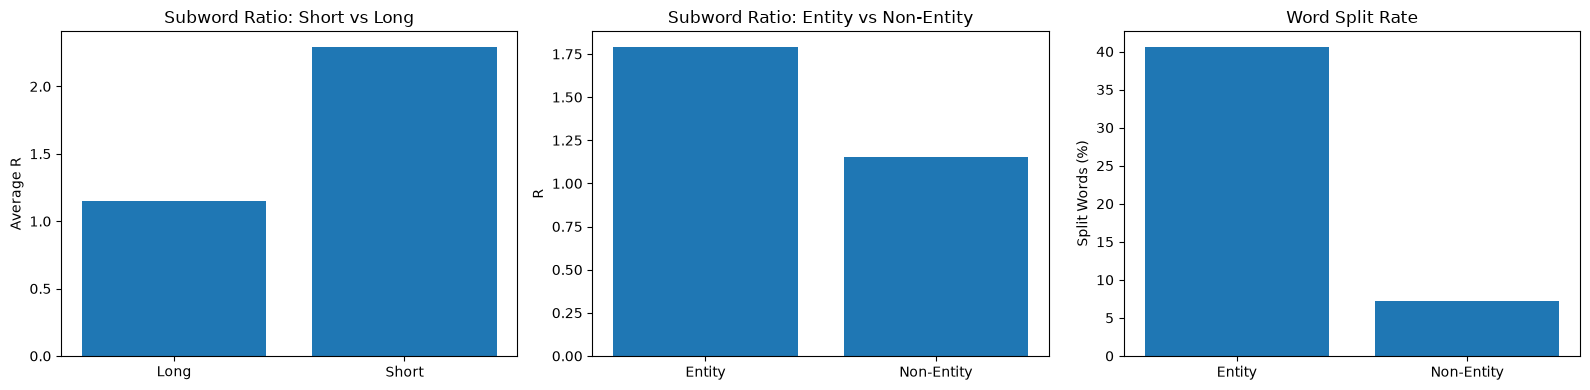

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Short vs Long
axes[0].bar(
    length_summary["group"],
    length_summary["avg_R"]
)
axes[0].set_title("Subword Ratio: Short vs Long")
axes[0].set_ylabel("Average R")

# 2. Entity vs Non-Entity
axes[1].bar(
    entity_summary["entity_type"],
    entity_summary["R"]
)
axes[1].set_title("Subword Ratio: Entity vs Non-Entity")
axes[1].set_ylabel("R")

# 3. Split rate
axes[2].bar(
    entity_summary["entity_type"],
    entity_summary["split_rate"] * 100
)
axes[2].set_title("Word Split Rate")
axes[2].set_ylabel("Split Words (%)")

plt.tight_layout()

plt.savefig(
    output_dir / "tokenization_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# Show words split into the most subwords
examples = (
    word_df[word_df["is_split"]]
    .sort_values("num_subwords", ascending=False)
    .head(30)
)

display(
    examples[
        [
            "word",
            "label",
            "entity_type",
            "num_subwords",
            "subwords"
        ]
    ]
)

,word,label,entity_type,num_subwords,subwords
103,double-bogeying,O,Non-Entity,6,double | - | b | ##og | ##ey | ##ing
34,AMSTERDAM,B-LOC,Entity,5,AM | ##ST | ##ER | ##DA | ##M
21,paedophile,O,Non-Entity,5,p | ##ae | ##do | ##phi | ##le
35,1996-08-31,O,Non-Entity,5,1996 | - | 08 | - | 31
43,DIVISION,I-MISC,Entity,5,D | ##I | ##VI | ##SI | ##ON
45,Colquhoun,I-PER,Entity,5,Col | ##q | ##uh | ##ou | ##n
47,1996-08-30,O,Non-Entity,5,1996 | - | 08 | - | 30
73,20-year-old,O,Non-Entity,5,20 | - | year | - | old
51,1996-08-30,O,Non-Entity,5,1996 | - | 08 | - | 30
66,MONTREAL,B-LOC,Entity,5,M | ##ON | ##TR | ##EA | ##L


# Experiment 3

In [42]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import accuracy_score
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

OUTPUT_DIR = Path("results/experiment3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

label_names = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

gold_sequences = [
    [label_names[int(tag)] for tag in ex["ner_tags"]]
    for ex in dev_dataset
]

baseline_predictions = baseline_model.predict(X_dev)

baseline_sequences = to_sequences(
    baseline_predictions,
    dev_lengths
)


# Keep evaluation complete: training inputs remain capped at MAX_LENGTH,
# but evaluation must include every word in each dev sentence.
dev_tokenized_full = dev_dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=dev_dataset.column_names,
    fn_kwargs={"truncation": False, "max_length": None},
)

max_model_length = model.config.max_position_embeddings
too_long = [
    i for i, input_ids in enumerate(dev_tokenized_full["input_ids"])
    if len(input_ids) > max_model_length
]
if too_long:
    raise ValueError(
        f"Dev sentence(s) {too_long[:5]} exceed BERT's maximum length "
        f"of {max_model_length} subwords."
    )

# Long, untruncated sentences use more memory; predict one at a time.
eval_batch_size = trainer.args.per_device_eval_batch_size
try:
    trainer.args.per_device_eval_batch_size = 1
    bert_output = trainer.predict(dev_tokenized_full)
finally:
    trainer.args.per_device_eval_batch_size = eval_batch_size

bert_logits = bert_output.predictions
bert_pred_ids = np.argmax(bert_logits, axis=-1)

bert_sequences = []

for pred_ids, label_ids in zip(
    bert_pred_ids,
    bert_output.label_ids
):
    sequence = [
        label_names[int(pred)]
        for pred, label in zip(pred_ids, label_ids)
        if label != -100
    ]
    bert_sequences.append(sequence)

assert len(gold_sequences) == len(baseline_sequences)
assert len(gold_sequences) == len(bert_sequences)

for gold, baseline_sequence, bert_sequence in zip(
    gold_sequences,
    baseline_sequences,
    bert_sequences
):
    assert len(gold) == len(baseline_sequence)
    assert len(gold) == len(bert_sequence)

print("All predictions aligned successfully!")

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

All predictions aligned successfully!


In [43]:
def evaluate_ner(gold, predictions, model_name):

    # Token-level accuracy
    flat_gold = [
        label for seq in gold for label in seq
    ]
    flat_pred = [
        label for seq in predictions for label in seq
    ]

    token_accuracy = accuracy_score(
        flat_gold, flat_pred
    )

    # Entity-level metrics
    entity_precision = precision_score(
        gold, predictions
    )
    entity_recall = recall_score(
        gold, predictions
    )
    entity_f1 = f1_score(
        gold, predictions
    )

    return {
        "Model": model_name,
        "Token Accuracy": token_accuracy,
        "Entity Precision": entity_precision,
        "Entity Recall": entity_recall,
        "Entity F1": entity_f1
    }


baseline_results = evaluate_ner(
    gold_sequences,
    baseline_sequences,
    "Logistic Regression"
)

bert_results = evaluate_ner(
    gold_sequences,
    bert_sequences,
    "BERT"
)

comparison_df = pd.DataFrame([
    baseline_results,
    bert_results
])

display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "token_vs_entity_metrics.csv",
    index=False
)

,Model,Token Accuracy,Entity Precision,Entity Recall,Entity F1
0,Logistic Regression,0.9677,0.7656,0.7938,0.7794
1,BERT,0.9877,0.9176,0.9309,0.9242


In [44]:
from seqeval.metrics.sequence_labeling import get_entities

def extract_entities(labels):
    return {
        (entity_type, start, end)
        for entity_type, start, end in get_entities(labels)
    }


def analyze_entity_errors(
    dataset,
    gold_sequences,
    pred_sequences,
    model_name
):
    records = []

    for sentence_id, (gold, pred) in enumerate(
        zip(gold_sequences, pred_sequences)
    ):
        tokens = dataset[sentence_id]["tokens"]

        gold_entities = extract_entities(gold)
        pred_entities = extract_entities(pred)

        # Exact matches
        correct = gold_entities & pred_entities

        # Missed entities
        missed = gold_entities - correct

        for entity_type, start, end in missed:

            # seqeval spans use inclusive end indices
            gold_text = " ".join(tokens[start:end + 1])

            overlapping = [
                (p_type, p_start, p_end)
                for p_type, p_start, p_end in pred_entities
                if p_start <= end and p_end >= start
            ]

            if overlapping:
                error_type = "Partial / Wrong Type"
                predicted_text = " | ".join(
                    " ".join(tokens[p_start:p_end + 1])
                    for _, p_start, p_end in overlapping
                )
            else:
                error_type = "Missed Entity"
                predicted_text = ""

            records.append({
                "Model": model_name,
                "Sentence ID": sentence_id,
                "Gold Entity": gold_text,
                "Gold Type": entity_type,
                "Predicted Overlap": predicted_text,
                "Error Type": error_type
            })

    return pd.DataFrame(records)


baseline_errors = analyze_entity_errors(
    dev_dataset,
    gold_sequences,
    baseline_sequences,
    "Logistic Regression"
)

bert_errors = analyze_entity_errors(
    dev_dataset,
    gold_sequences,
    bert_sequences,
    "BERT"
)

error_df = pd.concat(
    [baseline_errors, bert_errors],
    ignore_index=True
)

display(error_df.head(30))

error_df.to_csv(
    OUTPUT_DIR / "entity_errors.csv",
    index=False
)

,Model,Sentence ID,Gold Entity,Gold Type,Predicted Overlap,Error Type
0,Logistic Regression,0,Pro-Moscow,MISC,,Missed Entity
1,Logistic Regression,6,LIFFE,ORG,,Missed Entity
2,Logistic Regression,10,Changi Prison,LOC,Prison | Changi,Partial / Wrong Type
3,Logistic Regression,10,Central Narcotics Bureau,ORG,Bureau | Central Narcotics,Partial / Wrong Type
4,Logistic Regression,24,Bristol,LOC,Bristol,Partial / Wrong Type
5,Logistic Regression,26,Adams,PER,Adams,Partial / Wrong Type
6,Logistic Regression,26,Platt,PER,,Missed Entity
7,Logistic Regression,30,Michoacan,LOC,Michoacan,Partial / Wrong Type
8,Logistic Regression,31,UNITED NATIONS,ORG,NATIONS | UNITED,Partial / Wrong Type
9,Logistic Regression,46,Wasps,ORG,,Missed Entity


In [45]:
from seqeval.metrics import classification_report

print("=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)

print(classification_report(
    gold_sequences,
    baseline_sequences,
    digits=4
))

print("\n" + "=" * 60)
print("BERT")
print("=" * 60)

print(classification_report(
    gold_sequences,
    bert_sequences,
    digits=4
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

         LOC     0.8609    0.8490    0.8549       576
        MISC     0.8043    0.8014    0.8028       282
         ORG     0.6093    0.6544    0.6310       379
         PER     0.7632    0.8276    0.7941       557

   micro avg     0.7656    0.7938    0.7794      1794
   macro avg     0.7594    0.7831    0.7707      1794
weighted avg     0.7685    0.7938    0.7806      1794


BERT
              precision    recall  f1-score   support

         LOC     0.9496    0.9479    0.9487       576
        MISC     0.8396    0.8723    0.8557       282
         ORG     0.8648    0.8945    0.8794       379
         PER     0.9625    0.9677    0.9651       557

   micro avg     0.9176    0.9309    0.9242      1794
   macro avg     0.9041    0.9206    0.9122      1794
weighted avg     0.9184    0.9309    0.9245      1794



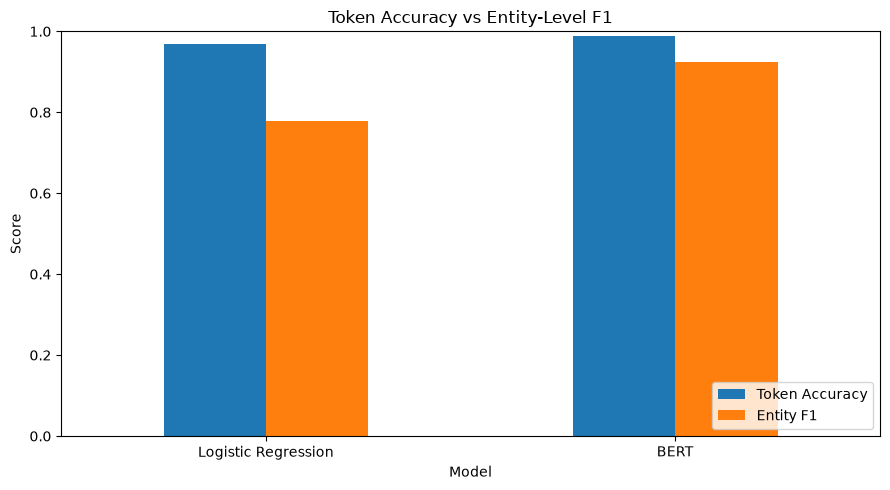

In [46]:
import matplotlib.pyplot as plt

plot_df = comparison_df.set_index("Model")[
    ["Token Accuracy", "Entity F1"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Token Accuracy vs Entity-Level F1")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "token_vs_entity_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 4

In [47]:
import numpy as np
import pandas as pd
from pathlib import Path

from seqeval.metrics import classification_report
from seqeval.scheme import IOB2

OUTPUT_DIR = Path("results/experiment4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]

def evaluate_entity_types(gold, pred, model_name):
    report = classification_report(
        gold,
        pred,
        output_dict=True,
        mode="strict",
        scheme=IOB2,
        zero_division=0
    )

    rows = []

    for entity in ENTITY_TYPES:
        metrics = report.get(entity, {})

        rows.append({
            "Model": model_name,
            "Entity": entity,
            "Precision": metrics.get("precision", 0),
            "Recall": metrics.get("recall", 0),
            "F1": metrics.get("f1-score", 0),
            "Support": metrics.get("support", 0)
        })

    return pd.DataFrame(rows)


baseline_entity_df = evaluate_entity_types(
    gold_sequences,
    baseline_sequences,
    "Logistic Regression"
)

bert_entity_df = evaluate_entity_types(
    gold_sequences,
    bert_sequences,
    "BERT"
)

entity_results_df = pd.concat(
    [baseline_entity_df, bert_entity_df],
    ignore_index=True
)

display(entity_results_df.round(4))

entity_results_df.to_csv(
    OUTPUT_DIR / "entity_type_metrics.csv",
    index=False
)

,Model,Entity,Precision,Recall,F1,Support
0,Logistic Regression,PER,0.8142,0.8259,0.8200,557
1,Logistic Regression,ORG,0.7206,0.6464,0.6815,379
2,Logistic Regression,LOC,0.8827,0.8490,0.8655,576
3,Logistic Regression,MISC,0.8459,0.7979,0.8212,282
4,BERT,PER,0.9642,0.9677,0.9659,557
5,BERT,ORG,0.8851,0.8945,0.8898,379
6,BERT,LOC,0.9577,0.9444,0.9510,576
7,BERT,MISC,0.8746,0.8652,0.8699,282


In [48]:
from collections import Counter
from seqeval.metrics.sequence_labeling import get_entities

label_names = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

def count_entities(dataset):
    counts = Counter()
    lengths = {entity: [] for entity in ENTITY_TYPES}
    unique_entities = {entity: set() for entity in ENTITY_TYPES}

    for example in dataset:
        tokens = example["tokens"]
        labels = [
            label_names[int(tag)]
            for tag in example["ner_tags"]
        ]

        for entity_type, start, end in get_entities(labels):
            counts[entity_type] += 1

            entity_length = end - start + 1
            lengths[entity_type].append(entity_length)

            entity_text = " ".join(
                tokens[start:end + 1]
            ).lower()

            unique_entities[entity_type].add(entity_text)

    rows = []

    for entity in ENTITY_TYPES:
        rows.append({
            "Entity": entity,
            "Train Count": counts[entity],
            "Unique Entities": len(unique_entities[entity]),
            "Avg Entity Length": (
                np.mean(lengths[entity])
                if lengths[entity] else 0
            )
        })

    return pd.DataFrame(rows)


train_stats_df = count_entities(train_dataset)

display(train_stats_df.round(4))

train_stats_df.to_csv(
    OUTPUT_DIR / "train_entity_distribution.csv",
    index=False
)

,Entity,Train Count,Unique Entities,Avg Entity Length
0,PER,2359,1648,1.6698
1,ORG,2181,1203,1.5635
2,LOC,2573,661,1.1586
3,MISC,1258,451,1.3680


In [49]:
analysis_df = entity_results_df.merge(
    train_stats_df,
    on="Entity",
    how="left"
)

analysis_df = analysis_df[
    [
        "Model",
        "Entity",
        "Train Count",
        "Unique Entities",
        "Avg Entity Length",
        "Precision",
        "Recall",
        "F1",
        "Support"
    ]
]

display(
    analysis_df.sort_values(
        ["Model", "F1"],
        ascending=[True, False]
    ).round(4)
)

analysis_df.to_csv(
    OUTPUT_DIR / "entity_type_analysis.csv",
    index=False
)

,Model,Entity,Train Count,Unique Entities,Avg Entity Length,Precision,Recall,F1,Support
4,BERT,PER,2359,1648,1.6698,0.9642,0.9677,0.9659,557
6,BERT,LOC,2573,661,1.1586,0.9577,0.9444,0.9510,576
5,BERT,ORG,2181,1203,1.5635,0.8851,0.8945,0.8898,379
7,BERT,MISC,1258,451,1.3680,0.8746,0.8652,0.8699,282
2,Logistic Regression,LOC,2573,661,1.1586,0.8827,0.8490,0.8655,576
3,Logistic Regression,MISC,1258,451,1.3680,0.8459,0.7979,0.8212,282
0,Logistic Regression,PER,2359,1648,1.6698,0.8142,0.8259,0.8200,557
1,Logistic Regression,ORG,2181,1203,1.5635,0.7206,0.6464,0.6815,379


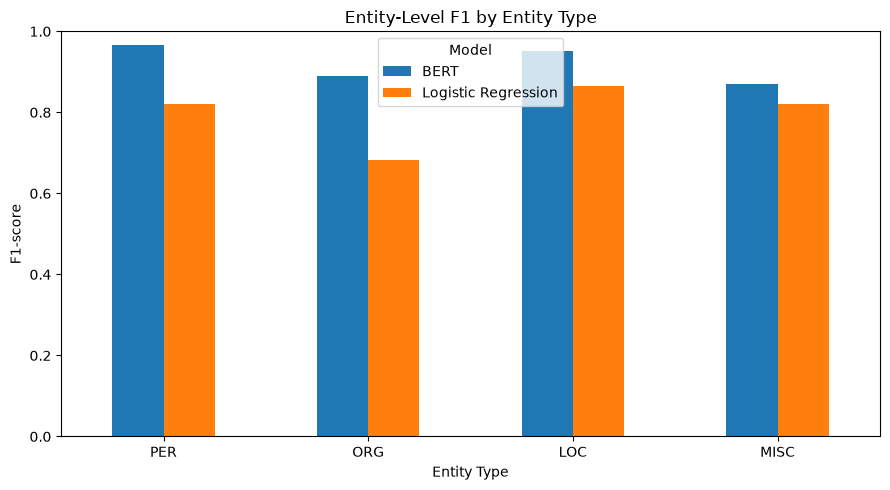

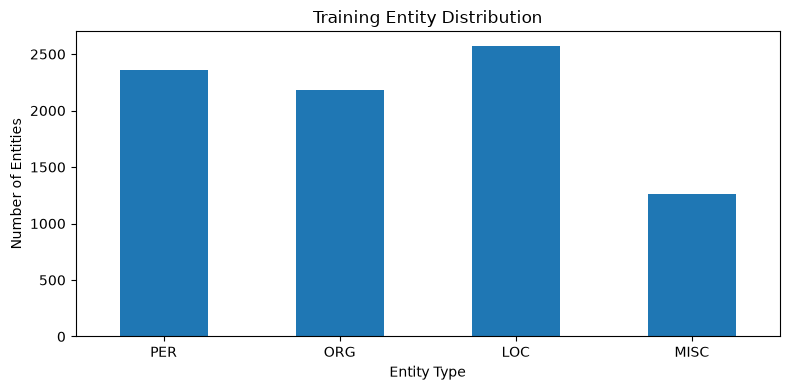

In [50]:
import matplotlib.pyplot as plt

# F1 comparison
f1_pivot = entity_results_df.pivot(
    index="Entity",
    columns="Model",
    values="F1"
).reindex(ENTITY_TYPES)

ax = f1_pivot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Entity-Level F1 by Entity Type")
ax.set_xlabel("Entity Type")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "entity_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Training distribution
ax = train_stats_df.set_index("Entity")[
    "Train Count"
].reindex(ENTITY_TYPES).plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

ax.set_title("Training Entity Distribution")
ax.set_xlabel("Entity Type")
ax.set_ylabel("Number of Entities")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "train_entity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [51]:
from collections import defaultdict

def collect_entity_records(data):
    records = []

    for example in data:
        tokens = example["tokens"]
        labels = [
            label_names[int(tag)]
            for tag in example["ner_tags"]
        ]

        for entity_type, start, end in get_entities(labels):
            text = " ".join(tokens[start:end + 1]).lower()

            records.append({
                "Entity": entity_type,
                "Text": text,
                "Length": end - start + 1
            })

    return pd.DataFrame(records)


train_entities = collect_entity_records(train_dataset)
dev_entities = collect_entity_records(dev_dataset)

# Entity texts observed in training
train_vocabulary = set(train_entities["Text"])

# Entity texts with multiple entity types in training
type_counts = train_entities.groupby("Text")["Entity"].nunique()
ambiguous_texts = set(type_counts[type_counts > 1].index)

rows = []

for entity in ENTITY_TYPES:
    subset = dev_entities[
        dev_entities["Entity"] == entity
    ]

    rows.append({
        "Entity": entity,
        "Dev Count": len(subset),
        "Multi-word Rate": (subset["Length"] > 1).mean(),
        "Unseen Rate": (~subset["Text"].isin(train_vocabulary)).mean(),
        "Ambiguous Rate": subset["Text"].isin(ambiguous_texts).mean()
    })

difficulty_df = pd.DataFrame(rows)

display(difficulty_df.round(4))

difficulty_df.to_csv(
    OUTPUT_DIR / "entity_difficulty_analysis.csv",
    index=False
)

,Entity,Dev Count,Multi-word Rate,Unseen Rate,Ambiguous Rate
0,PER,557,0.6679,0.7145,0.0036
1,ORG,379,0.2876,0.4301,0.1319
2,LOC,576,0.1545,0.1528,0.0851
3,MISC,282,0.2553,0.1915,0.0035


# Experiment 5

,Model,Entity Length,Support,Precision,Recall,F1
0,Logistic Regression,1,1152,0.7183,0.8255,0.7682
1,Logistic Regression,2,550,0.8909,0.8164,0.8520
2,Logistic Regression,3,65,0.7500,0.2769,0.4045
3,Logistic Regression,4+,27,0.7500,0.2222,0.3429
4,BERT,1,1152,0.9061,0.9384,0.9220
5,BERT,2,550,0.9481,0.9309,0.9394
6,BERT,3,65,0.8852,0.8308,0.8571
7,BERT,4+,27,0.8846,0.8519,0.8679


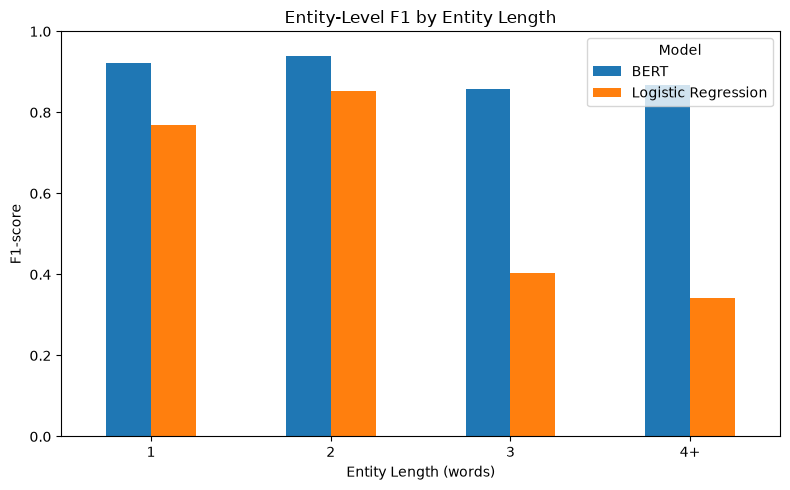

In [52]:
import pandas as pd
from pathlib import Path
from seqeval.metrics.sequence_labeling import get_entities

OUTPUT_DIR = Path("results/experiment5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def length_group(start, end):
    length = end - start + 1
    return str(length) if length <= 3 else "4+"

def evaluate_by_length(gold_sequences, pred_sequences, model_name):
    stats = {
        group: {"TP": 0, "FP": 0, "FN": 0}
        for group in ["1", "2", "3", "4+"]
    }

    for gold, pred in zip(gold_sequences, pred_sequences):
        gold_entities = set(get_entities(gold))
        pred_entities = set(get_entities(pred))

        for entity in gold_entities & pred_entities:
            group = length_group(entity[1], entity[2])
            stats[group]["TP"] += 1

        for entity in pred_entities - gold_entities:
            group = length_group(entity[1], entity[2])
            stats[group]["FP"] += 1

        for entity in gold_entities - pred_entities:
            group = length_group(entity[1], entity[2])
            stats[group]["FN"] += 1

    results = []

    for group, s in stats.items():
        tp, fp, fn = s["TP"], s["FP"], s["FN"]

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

        results.append({
            "Model": model_name,
            "Entity Length": group,
            "Support": tp + fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return pd.DataFrame(results)


# Evaluate
baseline_df = evaluate_by_length(
    gold_sequences, baseline_sequences, "Logistic Regression"
)

bert_df = evaluate_by_length(
    gold_sequences, bert_sequences, "BERT"
)

results_df = pd.concat([baseline_df, bert_df], ignore_index=True)

display(results_df.round(4))

# Save CSV
results_df.to_csv(
    OUTPUT_DIR / "entity_length_results.csv",
    index=False
)

# Plot
ax = results_df.pivot(
    index="Entity Length",
    columns="Model",
    values="F1"
).reindex(["1", "2", "3", "4+"]).plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
    ylim=(0, 1),
    title="Entity-Level F1 by Entity Length"
)

ax.set_ylabel("F1-score")
ax.set_xlabel("Entity Length (words)")

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "entity_length_f1.png",
    dpi=300,
    bbox_inches="tight"
)

# Application

In [53]:
import json
import torch
from transformers import pipeline

# 1. Load fine-tuned BERT NER
MODEL_PATH = "results/bert-ner/best-model"

ner_pipeline = pipeline(
    "token-classification",
    model=MODEL_PATH,
    tokenizer=MODEL_PATH,
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1
)

# 2. Map CoNLL-2003 labels to structured entity types
ENTITY_MAP = {
    "PER": "PERSON",
    "ORG": "ORGANIZATION",
    "LOC": "LOCATION",
    "MISC": "MISCELLANEOUS"
}

# 3. Information Extraction
def extract_information(text):
    predictions = ner_pipeline(text)

    result = {
        "PERSON": [],
        "ORGANIZATION": [],
        "LOCATION": [],
        "MISCELLANEOUS": []
    }

    for entity in predictions:
        entity_type = ENTITY_MAP.get(entity["entity_group"])

        if entity_type:
            value = text[entity["start"]:entity["end"]]

            if value not in result[entity_type]:
                result[entity_type].append(value)

    return {
        key: values
        for key, values in result.items()
        if values
    }

# 4. Test
texts = [
    "Barack Obama visited Paris.",
    "Microsoft was founded by Bill Gates.",
    "Google opened a new office in London.",
    "Elon Musk visited Germany."
]

for text in texts:
    print("\nInput:", text)
    print(json.dumps(
        extract_information(text),
        indent=4,
        ensure_ascii=False
    ))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Input: Barack Obama visited Paris.
{
    "PERSON": [
        "Barack Obama"
    ],
    "LOCATION": [
        "Paris"
    ]
}

Input: Microsoft was founded by Bill Gates.
{
    "PERSON": [
        "Bill Gates"
    ],
    "ORGANIZATION": [
        "Microsoft"
    ]
}

Input: Google opened a new office in London.
{
    "ORGANIZATION": [
        "Google"
    ],
    "LOCATION": [
        "London"
    ]
}

Input: Elon Musk visited Germany.
{
    "PERSON": [
        "El",
        "on Musk"
    ],
    "LOCATION": [
        "Germany"
    ]
}


# Mini Information Extraction Task

In [54]:
import json
import torch
from pathlib import Path
from transformers import pipeline

MODEL_PATH = "results/bert-ner/best-model"
OUTPUT_PATH = Path("results/option_a_news_ie.json")

ner = pipeline(
    task="token-classification",
    model=MODEL_PATH,
    tokenizer=MODEL_PATH,
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1
)

ENTITY_MAP = {
    "PER": "PERSON",
    "ORG": "ORG",
    "LOC": "LOCATION"
}

def extract_news_entities(text):
    predictions = ner(text)

    entities = {
        "PERSON": [],
        "ORG": [],
        "LOCATION": []
    }

    for pred in predictions:
        entity_type = ENTITY_MAP.get(pred["entity_group"])

        if entity_type is None:
            continue

        # Extract original text using character offsets
        entity_text = text[pred["start"]:pred["end"]]

        if entity_text not in entities[entity_type]:
            entities[entity_type].append(entity_text)

    return entities

news_articles = [
    "US President Joe Biden met with NATO leaders in Brussels.",

    "Microsoft announced a new investment in London.",

    "Google CEO Sundar Pichai visited Paris for a technology conference.",

    "Apple opened a new research center in Germany.",

    "United Nations officials met in New York to discuss climate change.",

    "Elon Musk attended an international technology summit in Berlin.",

    "Amazon announced plans to expand its operations in India.",

    "OpenAI CEO Sam Altman spoke at a conference in San Francisco.",

    "The World Health Organization held a meeting in Geneva.",

    "French President Emmanuel Macron visited Washington."
]


results = []

for i, article in enumerate(news_articles, start=1):
    extracted = extract_news_entities(article)

    results.append({
        "id": i,
        "text": article,
        "entities": extracted
    })

    print(f"\nNews {i}: {article}")
    print(json.dumps(extracted, indent=2, ensure_ascii=False))

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print(f"\nResults saved to: {OUTPUT_PATH.resolve()}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


News 1: US President Joe Biden met with NATO leaders in Brussels.
{
  "PERSON": [
    "Joe Biden"
  ],
  "ORG": [
    "NATO"
  ],
  "LOCATION": [
    "Brussels"
  ]
}

News 2: Microsoft announced a new investment in London.
{
  "PERSON": [],
  "ORG": [
    "Microsoft"
  ],
  "LOCATION": [
    "London"
  ]
}

News 3: Google CEO Sundar Pichai visited Paris for a technology conference.
{
  "PERSON": [
    "Sundar Pichai"
  ],
  "ORG": [
    "Google"
  ],
  "LOCATION": [
    "Paris"
  ]
}

News 4: Apple opened a new research center in Germany.
{
  "PERSON": [],
  "ORG": [
    "Apple"
  ],
  "LOCATION": [
    "Germany"
  ]
}

News 5: United Nations officials met in New York to discuss climate change.
{
  "PERSON": [],
  "ORG": [
    "United Nations"
  ],
  "LOCATION": [
    "New York"
  ]
}

News 6: Elon Musk attended an international technology summit in Berlin.
{
  "PERSON": [
    "El",
    "on Musk"
  ],
  "ORG": [],
  "LOCATION": [
    "Berlin"
  ]
}

News 7: Amazon announced plans to 

# Evaluation của Information Extraction

In [55]:
news_data = [
    ("Barack Obama visited Paris.", {"PERSON": ["Barack Obama"], "ORG": [], "LOCATION": ["Paris"]}),
    ("Microsoft opened an office in London.", {"PERSON": [], "ORG": ["Microsoft"], "LOCATION": ["London"]}),
    ("Google CEO Sundar Pichai visited India.", {"PERSON": ["Sundar Pichai"], "ORG": ["Google"], "LOCATION": ["India"]}),
    ("Apple announced a new product in California.", {"PERSON": [], "ORG": ["Apple"], "LOCATION": ["California"]}),
    ("Elon Musk met officials in Berlin.", {"PERSON": ["Elon Musk"], "ORG": [], "LOCATION": ["Berlin"]}),
    ("Amazon expanded operations in Germany.", {"PERSON": [], "ORG": ["Amazon"], "LOCATION": ["Germany"]}),
    ("Joe Biden attended a NATO meeting in Brussels.", {"PERSON": ["Joe Biden"], "ORG": ["NATO"], "LOCATION": ["Brussels"]}),
    ("United Nations officials gathered in New York.", {"PERSON": [], "ORG": ["United Nations"], "LOCATION": ["New York"]}),
    ("Sam Altman spoke at an OpenAI event in San Francisco.", {"PERSON": ["Sam Altman"], "ORG": ["OpenAI"], "LOCATION": ["San Francisco"]}),
    ("Emmanuel Macron visited Washington.", {"PERSON": ["Emmanuel Macron"], "ORG": [], "LOCATION": ["Washington"]}),
    ("Tesla opened a factory in Texas.", {"PERSON": [], "ORG": ["Tesla"], "LOCATION": ["Texas"]}),
    ("Bill Gates attended a conference in Tokyo.", {"PERSON": ["Bill Gates"], "ORG": [], "LOCATION": ["Tokyo"]}),
    ("Meta announced a partnership with Microsoft.", {"PERSON": [], "ORG": ["Meta", "Microsoft"], "LOCATION": []}),
    ("NASA launched a mission from Florida.", {"PERSON": [], "ORG": ["NASA"], "LOCATION": ["Florida"]}),
    ("Tim Cook visited China.", {"PERSON": ["Tim Cook"], "ORG": [], "LOCATION": ["China"]}),
    ("IBM established a research center in Zurich.", {"PERSON": [], "ORG": ["IBM"], "LOCATION": ["Zurich"]}),
    ("Angela Merkel attended a summit in Paris.", {"PERSON": ["Angela Merkel"], "ORG": [], "LOCATION": ["Paris"]}),
    ("Samsung expanded its business in Vietnam.", {"PERSON": [], "ORG": ["Samsung"], "LOCATION": ["Vietnam"]}),
    ("Mark Zuckerberg met investors in London.", {"PERSON": ["Mark Zuckerberg"], "ORG": [], "LOCATION": ["London"]}),
    ("UNICEF launched a program in Kenya.", {"PERSON": [], "ORG": ["UNICEF"], "LOCATION": ["Kenya"]}),
    ("Jeff Bezos visited Seattle.", {"PERSON": ["Jeff Bezos"], "ORG": [], "LOCATION": ["Seattle"]}),
    ("Intel announced a new facility in Ohio.", {"PERSON": [], "ORG": ["Intel"], "LOCATION": ["Ohio"]}),
    ("Cristiano Ronaldo traveled to Madrid.", {"PERSON": ["Cristiano Ronaldo"], "ORG": [], "LOCATION": ["Madrid"]}),
    ("Sony opened a new office in Singapore.", {"PERSON": [], "ORG": ["Sony"], "LOCATION": ["Singapore"]}),
    ("Satya Nadella met officials in Washington.", {"PERSON": ["Satya Nadella"], "ORG": [], "LOCATION": ["Washington"]}),
    ("WHO held a conference in Geneva.", {"PERSON": [], "ORG": ["WHO"], "LOCATION": ["Geneva"]}),
    ("Alibaba expanded operations in Malaysia.", {"PERSON": [], "ORG": ["Alibaba"], "LOCATION": ["Malaysia"]}),
    ("Jensen Huang presented NVIDIA technology in Taipei.", {"PERSON": ["Jensen Huang"], "ORG": ["NVIDIA"], "LOCATION": ["Taipei"]}),
    ("The European Union met in Brussels.", {"PERSON": [], "ORG": ["European Union"], "LOCATION": ["Brussels"]}),
    ("Larry Page founded Google in California.", {"PERSON": ["Larry Page"], "ORG": ["Google"], "LOCATION": ["California"]}),
]

print("Total evaluation sentences:", len(news_data))

Total evaluation sentences: 30


In [56]:
import pandas as pd
from pathlib import Path
from collections import defaultdict

OUTPUT_DIR = Path("results/ie_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ENTITY_TYPES = ["PERSON", "ORG", "LOCATION"]

def normalize_entities(entities):
    return {
        (entity_type, value.strip())
        for entity_type, values in entities.items()
        for value in values
        if entity_type in ENTITY_TYPES
    }

stats = defaultdict(lambda: {"TP": 0, "FP": 0, "FN": 0})
error_records = []

for sentence_id, (text, gold) in enumerate(news_data, start=1):
    pred = extract_news_entities(text)

    gold_set = normalize_entities(gold)
    pred_set = normalize_entities(pred)

    for entity_type in ENTITY_TYPES:
        gold_type = {
            item for item in gold_set if item[0] == entity_type
        }
        pred_type = {
            item for item in pred_set if item[0] == entity_type
        }

        tp = gold_type & pred_type
        fp = pred_type - gold_type
        fn = gold_type - pred_type

        stats[entity_type]["TP"] += len(tp)
        stats[entity_type]["FP"] += len(fp)
        stats[entity_type]["FN"] += len(fn)

        for label, items in [("FP", fp), ("FN", fn)]:
            for _, value in items:
                error_records.append({
                    "Sentence ID": sentence_id,
                    "Text": text,
                    "Entity Type": entity_type,
                    "Entity": value,
                    "Error": label
                })

# Calculate per-entity metrics
results = []

for entity_type in ENTITY_TYPES:
    s = stats[entity_type]
    tp, fp, fn = s["TP"], s["FP"], s["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "Entity": entity_type,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

# Micro-average across entity types
total_tp = sum(s["TP"] for s in stats.values())
total_fp = sum(s["FP"] for s in stats.values())
total_fn = sum(s["FN"] for s in stats.values())

micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0
micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0
micro_f1 = (
    2 * micro_precision * micro_recall / (micro_precision + micro_recall)
    if micro_precision + micro_recall else 0
)

results.append({
    "Entity": "Micro Average",
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "Precision": micro_precision,
    "Recall": micro_recall,
    "F1": micro_f1
})

results_df = pd.DataFrame(results)
errors_df = pd.DataFrame(
    error_records,
    columns=["Sentence ID", "Text", "Entity Type", "Entity", "Error"]
)

display(results_df.round(4))

results_df.to_csv(
    OUTPUT_DIR / "ie_metrics.csv",
    index=False
)

errors_df.to_csv(
    OUTPUT_DIR / "ie_errors.csv",
    index=False
)

print(f"Results saved to: {OUTPUT_DIR.resolve()}")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,Entity,TP,FP,FN,Precision,Recall,F1
0,PERSON,12,7,3,0.6316,0.8000,0.7059
1,ORG,19,0,2,1.0000,0.9048,0.9500
2,LOCATION,29,0,0,1.0000,1.0000,1.0000
3,Micro Average,60,7,5,0.8955,0.9231,0.9091


Results saved to: /home/vitquay1708/Study_Space/NLP/lab9/results/ie_evaluation
